# Relate Geospatial Notebook

This notebook demonstrates Relate's geospatial capabilities and shows how to integrate with the Python geospatial ecosystem.

**Relate geo features covered:**
- `point()` constructor (geographic & cartesian)
- `point.distance()` — Haversine (geographic) and Euclidean (cartesian)
- `point.withinBBox()` — bounding box filtering
- radius and distance-band filters as `point.distance(...) < bound`
- point coordinates as plain properties (`p.latitude` / `p.longitude`)
- 3D points with elevation
- R-tree point indexes

Geometry work (routes, regions) is Python-side in this notebook: a geometry
travels as an ordinary property (a GeoJSON string), and Shapely / GeoPandas do
the computation over the coordinates the graph returns.

**Python library integrations:**
- [GeoPandas](https://geopandas.org/) — spatial DataFrames
- [Folium](https://python-visualization.github.io/folium/) — interactive Leaflet maps
- [Shapely](https://shapely.readthedocs.io/) — computational geometry
- [H3](https://uber.github.io/h3-py/) — hexagonal spatial indexing
- [OSMnx](https://osmnx.readthedocs.io/) — OpenStreetMap network import
- [MovingPandas](https://movingpandas.org/) — trajectory analysis
- [Leafmap](https://leafmap.org/) — interactive mapping
- [Pandana](https://udst.github.io/pandana/) — network accessibility analysis

### Prerequisites

Relate is not yet on PyPI — build it from a checkout of the repository (requires the Rust toolchain):

```bash
cd surfaces/relate-python && pip install maturin && maturin develop --release
```

Then install the geospatial ecosystem libraries used in this notebook:

```bash
pip install geopandas folium shapely h3 osmnx movingpandas leafmap pandana matplotlib
```

In [1]:
# --- Setup ------------------------------------------------------------------
# Install Relate and this notebook's geospatial stack into the current
# kernel if they are not already present. Relate is not yet on PyPI, so it
# is built from this repository checkout (requires the Rust toolchain,
# https://rustup.rs) -- the same maturin build that `make install-python` runs.
# Once published, the Relate line becomes a plain `pip install relate`.
import importlib
import warnings
import subprocess
import sys


def _ensure(module, pip_spec):
    try:
        # Silence import-time warnings from optional deps (e.g. movingpandas'
        # optional-dependency notice) so probing stays quiet and path-free.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            importlib.import_module(module)
    except ImportError:
        print(f"Installing {pip_spec} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pip_spec.split()])


_ensure("relate", "../surfaces/relate-python")  # local build (pre-PyPI)
for _mod, _spec in [
    ("pandas", "pandas"),
    ("numpy", "numpy"),
    ("geopandas", "geopandas"),
    ("shapely", "shapely"),
    ("matplotlib", "matplotlib"),
    ("folium", "folium"),
    ("h3", "h3"),
    ("networkx", "networkx"),
    ("osmnx", "osmnx"),
    ("movingpandas", "movingpandas"),
    ("cartopy", "cartopy"),
    ("leafmap", "leafmap"),
]:
    _ensure(_mod, _spec)


In [2]:
import relate

db = relate.connect(":memory:")
print(f"Relate {relate.__version__} connected")

Relate 0.3.0a0 connected


---
## 1. Points and Distance

Relate supports geographic points (latitude/longitude, distance in meters via Haversine) and cartesian points (x/y, Euclidean distance).

In [3]:
# Geographic distance: New York to Los Angeles
cursor = db.execute(
    "RETURN point.distance("
    "  point({latitude: 40.7128, longitude: -74.0060}),"
    "  point({latitude: 34.0522, longitude: -118.2437})"
    ") AS dist_meters"
)
row = cursor.fetchone()
print(f"NYC to LA: {row['dist_meters']:,.0f} meters ({row['dist_meters'] / 1000:,.0f} km)")

NYC to LA: 3,935,752 meters (3,936 km)


In [4]:
# Cartesian distance
cursor = db.execute(
    "RETURN point.distance(point({x: 0, y: 0}), point({x: 3, y: 4})) AS dist"
)
print(f"Cartesian distance (3,4 triangle): {cursor.fetchone()['dist']}")

Cartesian distance (3,4 triangle): 5.0


---
## 2. Build a City Graph

Create nodes with point properties representing major US cities.

In [5]:
cities = [
    {"name": "New York",      "state": "NY", "lat": 40.7128, "lon": -74.0060, "pop": 8336817},
    {"name": "Los Angeles",   "state": "CA", "lat": 34.0522, "lon": -118.2437, "pop": 3979576},
    {"name": "Chicago",       "state": "IL", "lat": 41.8781, "lon": -87.6298,  "pop": 2693976},
    {"name": "Houston",       "state": "TX", "lat": 29.7604, "lon": -95.3698,  "pop": 2320268},
    {"name": "Phoenix",       "state": "AZ", "lat": 33.4484, "lon": -112.0740, "pop": 1680992},
    {"name": "Philadelphia",  "state": "PA", "lat": 39.9526, "lon": -75.1652,  "pop": 1603797},
    {"name": "San Antonio",   "state": "TX", "lat": 29.4241, "lon": -98.4936,  "pop": 1547253},
    {"name": "San Diego",     "state": "CA", "lat": 32.7157, "lon": -117.1611, "pop": 1423851},
    {"name": "Dallas",        "state": "TX", "lat": 32.7767, "lon": -96.7970,  "pop": 1343573},
    {"name": "San Francisco", "state": "CA", "lat": 37.7749, "lon": -122.4194, "pop": 873965},
    {"name": "Seattle",       "state": "WA", "lat": 47.6062, "lon": -122.3321, "pop": 749256},
    {"name": "Denver",        "state": "CO", "lat": 39.7392, "lon": -104.9903, "pop": 715522},
    {"name": "Portland",      "state": "OR", "lat": 45.5152, "lon": -122.6784, "pop": 652573},
    {"name": "Miami",         "state": "FL", "lat": 25.7617, "lon": -80.1918,  "pop": 467963},
    {"name": "Atlanta",       "state": "GA", "lat": 33.7490, "lon": -84.3880,  "pop": 498715},
    {"name": "Boston",        "state": "MA", "lat": 42.3601, "lon": -71.0589,  "pop": 692600},
]

for c in cities:
    db.execute(
        "CREATE (:City {name: $name, state: $state, population: $pop, "
        "location: point({latitude: $lat, longitude: $lon})})",
        c,
    )

print(f"Created {len(cities)} cities")

Created 16 cities


In [6]:
# Create a spatial index on city locations
db.execute("CREATE POINT INDEX city_location_idx FOR (c:City) ON (c.location)")
print("Spatial index created")

Spatial index created


---
## 3. Radius Search with `point.distance()`

Find all cities within a given radius of a reference point: the filter is a
distance comparison in meters, the shape a `POINT INDEX` seek recognizes.

In [ ]:
# Cities within 500 km of New York
cursor = db.execute(
    "MATCH (c:City) "
    "WHERE point.distance(c.location, "
    "  point({latitude: 40.7128, longitude: -74.0060})) < 500000 "
    "RETURN c.name AS city, c.state AS state, "
    "  point.distance(c.location, point({latitude: 40.7128, longitude: -74.0060})) / 1000 AS km "
    "ORDER BY km"
)

print("Cities within 500 km of New York:")
for row in cursor:
    print(f"  {row['city']}, {row['state']:2s} — {row['km']:,.0f} km")

---
## 4. Bounding Box Search with `point.withinBBox()`

Find all cities within a rectangular geographic region.

In [8]:
# Cities in the US West Coast bounding box (lat 32-48, lon -125 to -115)
cursor = db.execute(
    "MATCH (c:City) "
    "WHERE point.withinBBox(c.location, "
    "  point({latitude: 32.0, longitude: -125.0}), "
    "  point({latitude: 48.0, longitude: -115.0})) "
    "RETURN c.name AS city, c.state AS state, c.population AS pop "
    "ORDER BY c.population DESC"
)

print("West Coast cities (bounding box):")
for row in cursor:
    print(f"  {row['city']}, {row['state']} — pop {row['pop']:,}")

West Coast cities (bounding box):
  Los Angeles, CA — pop 3,979,576
  San Diego, CA — pop 1,423,851
  San Francisco, CA — pop 873,965
  Seattle, WA — pop 749,256
  Portland, OR — pop 652,573


---
## 5. Reading Points into Python

Point coordinates are ordinary properties (`p.latitude` / `p.longitude`, or
`p.x` / `p.y`), so they cross into Python without a conversion function.
Geometry formats are a host-language concern: build GeoJSON or WKT in Python
from those coordinates, and keep geometry properties as ordinary strings.

In [ ]:
# Point → coordinates
cursor = db.execute(
    "MATCH (c:City {name: 'Seattle'}) "
    "RETURN c.name AS city, c.location.latitude AS lat, c.location.longitude AS lon"
)
row = cursor.fetchone()
print(f"{row['city']}: ({row['lat']}, {row['lon']})")

In [ ]:
# Coordinates → point (round-trip through parameters)
cursor = db.execute(
    "RETURN point({latitude: $lat, longitude: $lon}) AS pt",
    {"lat": 39.7392, "lon": -104.9903},
)
pt = cursor.fetchone()["pt"]
print(f"Point: ({pt.latitude}, {pt.longitude})")

In [ ]:
# GeoJSON from those coordinates — plain Python dict work
geojson = {"type": "Point", "coordinates": [pt.longitude, pt.latitude]}
print(f"GeoJSON: {geojson}")

In [ ]:
# Geometry travels as an ordinary property: store each city's GeoJSON once
import json

for row in db.execute(
    "MATCH (c:City) "
    "RETURN c.name AS name, c.location.latitude AS lat, c.location.longitude AS lon"
):
    db.execute(
        "MATCH (c:City {name: $name}) SET c.geojson = $geojson",
        {
            "name": row["name"],
            "geojson": json.dumps(
                {"type": "Point", "coordinates": [row["lon"], row["lat"]]}
            ),
        },
    )

print(db.execute(
    "MATCH (c:City {name: 'Denver'}) RETURN c.geojson AS geojson"
).fetchone()["geojson"])

---
## 6. Distance Bands and Nearest Neighbours

`point.distance()` is the workhorse: rank every city by distance to a reference
point, then slice the ranking into nearest-N and distance-band queries.

In [ ]:
# Nearest cities to Denver
cursor = db.execute(
    "MATCH (c:City), (ref:City {name: 'Denver'}) "
    "WHERE c.name <> ref.name "
    "WITH c, point.distance(c.location, ref.location) AS dist "
    "RETURN c.name AS city, c.state AS state, dist / 1000 AS km "
    "ORDER BY km LIMIT 5"
)

print("Five cities nearest Denver:")
for row in cursor:
    print(f"  {row['city']}, {row['state']:2s} — {row['km']:,.0f} km")

In [ ]:
# A distance band: 500–1500 km from Chicago
cursor = db.execute(
    "MATCH (c:City), (ref:City {name: 'Chicago'}) "
    "WITH c, point.distance(c.location, ref.location) AS dist "
    "WHERE dist >= 500000 AND dist <= 1500000 "
    "RETURN c.name AS city, dist / 1000 AS km "
    "ORDER BY km"
)

print("Cities 500–1500 km from Chicago:")
for row in cursor:
    print(f"  {row['city']}: {row['km']:,.0f} km")

---
## 6b. Distance as a Join Filter

Filtering a pair of variables by `point.distance()` answers proximity
questions that whole-graph scans miss: which cities are within a day's drive of
each other?

In [ ]:
# City pairs closer than 800 km (distance as a join filter)
cursor = db.execute(
    "MATCH (a:City), (b:City) "
    "WHERE a.name < b.name "
    "  AND point.distance(a.location, b.location) < 800000 "
    "RETURN a.name AS a, b.name AS b, "
    "  toInteger(round(point.distance(a.location, b.location) / 1000)) AS km "
    "ORDER BY km"
)

print("City pairs within 800 km:")
for row in cursor:
    print(f"  {row['a']} — {row['b']}: {row['km']:,} km")

---
## 6c. Distance Aggregates

Aggregate over distances: how far is each state's average city from New York?

In [ ]:
# Mean distance from each state's cities to New York
cursor = db.execute(
    "MATCH (c:City), (nyc:City {name: 'New York'}) "
    "WHERE c.name <> nyc.name "
    "WITH c.state AS state, point.distance(c.location, nyc.location) / 1000 AS km "
    "RETURN state, toInteger(round(avg(km))) AS avg_km, count(*) AS cities "
    "ORDER BY avg_km"
)

print("Mean distance to New York, by state:")
for row in cursor:
    print(f"  {row['state']}: {row['avg_km']:,} km ({row['cities']} cities)")

---
## 7. 3D Points with Elevation

Relate supports 3D geographic points with a `height` component (meters above sea level). Distance calculations account for elevation differences.

In [17]:
# Create airports with elevation
airports = [
    {"code": "DEN", "name": "Denver International",   "lat": 39.8561, "lon": -104.6737, "elev": 1655},
    {"code": "LAX", "name": "Los Angeles International", "lat": 33.9425, "lon": -118.4081, "elev": 38},
    {"code": "JFK", "name": "John F. Kennedy",         "lat": 40.6413, "lon": -73.7781,  "elev": 4},
    {"code": "SFO", "name": "San Francisco International", "lat": 37.6213, "lon": -122.3790, "elev": 4},
    {"code": "SEA", "name": "Seattle-Tacoma",          "lat": 47.4502, "lon": -122.3088, "elev": 137},
]

for a in airports:
    db.execute(
        "CREATE (:Airport {code: $code, name: $name, "
        "location: point({latitude: $lat, longitude: $lon, height: $elev})})",
        a,
    )

# 3D distance between Denver (1655m) and LAX (38m)
cursor = db.execute(
    "MATCH (a:Airport {code: 'DEN'}), (b:Airport {code: 'LAX'}) "
    "RETURN point.distance(a.location, b.location) AS dist_3d"
)
dist = cursor.fetchone()["dist_3d"]
print(f"DEN → LAX (3D, including elevation): {dist / 1000:,.1f} km")

DEN → LAX (3D, including elevation): 1,384.8 km


In [ ]:
# A 3D point keeps its elevation as a property, so the GeoJSON shape is Python work
cursor = db.execute(
    "MATCH (a:Airport {code: 'DEN'}) "
    "RETURN a.location.latitude AS lat, a.location.longitude AS lon, "
    "  a.location.height AS height"
)
row = cursor.fetchone()
print(
    "DEN GeoJSON: "
    f"{{\"type\": \"Point\", \"coordinates\": [{row['lon']}, {row['lat']}, {row['height']}]}}"
)

---
## 8. Flight Routes Between Airports

Create relationships with distance as a property.

In [19]:
# Create flight routes and store distance
routes = [("JFK", "LAX"), ("JFK", "SFO"), ("JFK", "SEA"), ("LAX", "SFO"),
          ("LAX", "SEA"), ("DEN", "JFK"), ("DEN", "LAX"), ("DEN", "SFO"),
          ("SFO", "SEA"), ("DEN", "SEA")]

for orig, dest in routes:
    db.execute(
        "MATCH (a:Airport {code: $orig}), (b:Airport {code: $dest}) "
        "CREATE (a)-[:ROUTE {distance_km: point.distance(a.location, b.location) / 1000}]->(b)",
        {"orig": orig, "dest": dest},
    )

# Query routes sorted by distance
cursor = db.execute(
    "MATCH (a:Airport)-[r:ROUTE]->(b:Airport) "
    "RETURN a.code AS origin, b.code AS destination, r.distance_km AS km "
    "ORDER BY km DESC"
)

print("Flight routes by distance:")
for row in cursor:
    print(f"  {row['origin']} → {row['destination']}: {row['km']:,.0f} km")

Flight routes by distance:
  JFK → SFO: 4,152 km
  JFK → LAX: 3,974 km
  JFK → SEA: 3,887 km
  DEN → JFK: 2,610 km
  DEN → SEA: 1,645 km
  DEN → SFO: 1,553 km
  LAX → SEA: 1,537 km
  DEN → LAX: 1,385 km
  SFO → SEA: 1,093 km
  LAX → SFO: 544 km


---
## 9. Helper: Query Results to Python Dicts

A small helper to extract city data for use with geo libraries.

In [20]:
def query_cities(db):
    """Fetch all cities with their coordinates from Relate."""
    cursor = db.execute(
        "MATCH (c:City) "
        "RETURN c.name AS name, c.state AS state, c.population AS pop, "
        "  c.location.latitude AS lat, c.location.longitude AS lon "
        "ORDER BY pop DESC"
    )
    return cursor.fetchall()


def query_airports(db):
    """Fetch all airports with coordinates from Relate."""
    cursor = db.execute(
        "MATCH (a:Airport) "
        "RETURN a.code AS code, a.name AS name, "
        "  a.location.latitude AS lat, a.location.longitude AS lon "
        "ORDER BY code"
    )
    return cursor.fetchall()


def query_routes(db):
    """Fetch all flight routes with endpoint coordinates."""
    cursor = db.execute(
        "MATCH (a:Airport)-[r:ROUTE]->(b:Airport) "
        "RETURN a.code AS orig, a.location.latitude AS orig_lat, a.location.longitude AS orig_lon, "
        "  b.code AS dest, b.location.latitude AS dest_lat, b.location.longitude AS dest_lon, "
        "  r.distance_km AS km"
    )
    return cursor.fetchall()


city_data = query_cities(db)
airport_data = query_airports(db)
route_data = query_routes(db)
print(f"{len(city_data)} cities, {len(airport_data)} airports, {len(route_data)} routes")

16 cities, 5 airports, 10 routes


---
## 10. GeoPandas — Spatial DataFrames

Convert Relate query results into a GeoPandas `GeoDataFrame` for spatial analysis.

In [21]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point

# Build GeoDataFrame from Relate results
df = pd.DataFrame(city_data)
geometry = [Point(row["lon"], row["lat"]) for row in city_data]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")

print(gdf[["name", "state", "pop", "geometry"]].to_string(index=False))

         name state     pop                  geometry
     New York    NY 8336817   POINT (-74.006 40.7128)
  Los Angeles    CA 3979576 POINT (-118.2437 34.0522)
      Chicago    IL 2693976  POINT (-87.6298 41.8781)
      Houston    TX 2320268  POINT (-95.3698 29.7604)
      Phoenix    AZ 1680992  POINT (-112.074 33.4484)
 Philadelphia    PA 1603797  POINT (-75.1652 39.9526)
  San Antonio    TX 1547253  POINT (-98.4936 29.4241)
    San Diego    CA 1423851 POINT (-117.1611 32.7157)
       Dallas    TX 1343573   POINT (-96.797 32.7767)
San Francisco    CA  873965 POINT (-122.4194 37.7749)
      Seattle    WA  749256 POINT (-122.3321 47.6062)
       Denver    CO  715522 POINT (-104.9903 39.7392)
       Boston    MA  692600  POINT (-71.0589 42.3601)
     Portland    OR  652573 POINT (-122.6784 45.5152)
      Atlanta    GA  498715    POINT (-84.388 33.749)
        Miami    FL  467963  POINT (-80.1918 25.7617)


In [22]:
# Spatial operation: buffer each city by ~50 km and check overlaps
# Project to a meter-based CRS for accurate buffering
gdf_proj = gdf.to_crs(epsg=5070)  # Conus Albers Equal Area
gdf_proj["buffer_50km"] = gdf_proj.geometry.buffer(50_000)

# Find pairs of cities whose 50km buffers overlap
pairs = []
for i, row_a in gdf_proj.iterrows():
    for j, row_b in gdf_proj.iterrows():
        if i < j and row_a["buffer_50km"].intersects(row_b["buffer_50km"]):
            pairs.append((row_a["name"], row_b["name"]))

print("City pairs within ~100 km of each other (overlapping 50 km buffers):")
for a, b in pairs:
    print(f"  {a} ↔ {b}")

if not pairs:
    print("  (no overlapping pairs — these major cities are spread out)")

City pairs within ~100 km of each other (overlapping 50 km buffers):
  (no overlapping pairs — these major cities are spread out)


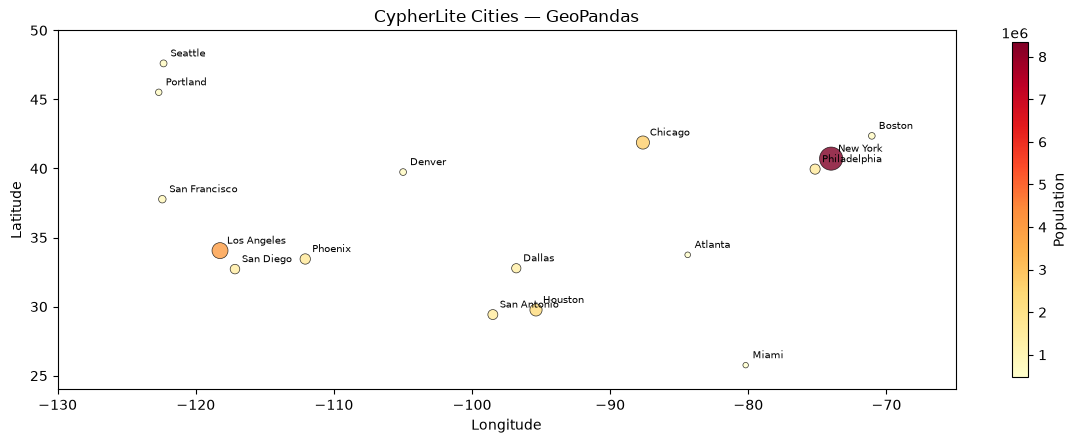

In [23]:
# Plot cities on a map with matplotlib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(12, 7))

# Plot city points sized by population
gdf.plot(ax=ax, column="pop", legend=True, markersize=gdf["pop"] / 30000,
         cmap="YlOrRd", alpha=0.8, edgecolor="black", linewidth=0.5,
         legend_kwds={"label": "Population", "shrink": 0.5})

for _, row in gdf.iterrows():
    ax.annotate(row["name"], xy=(row["lon"], row["lat"]),
                xytext=(5, 5), textcoords="offset points", fontsize=7)

ax.set_xlim(-130, -65)
ax.set_ylim(24, 50)
ax.set_title("Relate Cities — GeoPandas")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

---
## 11. Shapely — Computational Geometry

Build Shapely geometries from the coordinates Relate returns and perform
geometric operations in Python.

In [ ]:
from shapely.geometry import MultiPoint, Point

# Read city coordinates from Relate
cursor = db.execute(
    "MATCH (c:City) "
    "RETURN c.name AS name, c.location.latitude AS lat, c.location.longitude AS lon "
    "ORDER BY c.population DESC"
)

points = []
for row in cursor:
    pt = Point(row["lon"], row["lat"])
    points.append(pt)
    if len(points) <= 3:
        print(f"  {row['name']}: {pt}")

# Compute convex hull of all city locations
mp = MultiPoint(points)
hull = mp.convex_hull
print(f"\nConvex hull of {len(points)} cities:")
print(f"  Type: {hull.geom_type}")
print(f"  Bounds: {hull.bounds}")
print(f"  Area (sq degrees): {hull.area:.2f}")

In [25]:
# Load the convex hull centroid back into Relate
centroid = hull.centroid
# Shapely centroid gives (lon, lat) since our points were (lon, lat)
centroid_lon, centroid_lat = centroid.x, centroid.y

cursor = db.execute(
    "MATCH (c:City) "
    "WITH c, point.distance(c.location, "
    "  point({latitude: $lat, longitude: $lon})) AS dist "
    "RETURN c.name AS city, dist / 1000 AS km_from_centroid "
    "ORDER BY km_from_centroid LIMIT 3",
    {"lat": centroid_lat, "lon": centroid_lon},
)

print(f"Centroid of city convex hull: ({centroid_lat:.2f}°N, {centroid_lon:.2f}°W)")
print("Three closest cities to centroid:")
for row in cursor:
    print(f"  {row['city']}: {row['km_from_centroid']:,.0f} km")

Centroid of city convex hull: (37.49°N, -97.69°W)
Three closest cities to centroid:
  Dallas: 530 km
  Denver: 681 km
  Houston: 886 km


---
## 12. Folium — Interactive Leaflet Maps

Visualize Relate results on an interactive map.

In [26]:
import folium

m = folium.Map(location=[39.0, -98.0], zoom_start=4, tiles="cartodbpositron")

# Add city markers
for row in city_data:
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=max(3, row["pop"] / 500000),
        color="#e74c3c",
        fill=True,
        fill_opacity=0.7,
        popup=f"{row['name']}, {row['state']} (pop {row['pop']:,})",
        tooltip=row["name"],
    ).add_to(m)

# Add airport markers and flight routes
for ap in airport_data:
    folium.Marker(
        location=[ap["lat"], ap["lon"]],
        icon=folium.Icon(icon="plane", prefix="fa", color="blue"),
        popup=f"{ap['code']} — {ap['name']}",
        tooltip=ap["code"],
    ).add_to(m)

for rt in route_data:
    folium.PolyLine(
        locations=[[rt["orig_lat"], rt["orig_lon"]], [rt["dest_lat"], rt["dest_lon"]]],
        weight=1.5,
        color="#3498db",
        opacity=0.6,
        tooltip=f"{rt['orig']}→{rt['dest']} ({rt['km']:,.0f} km)",
    ).add_to(m)

# Draw a 500 km radius circle around New York
folium.Circle(
    location=[40.7128, -74.0060],
    radius=500_000,
    color="green",
    fill=True,
    fill_opacity=0.08,
    tooltip="500 km radius from NYC",
).add_to(m)

m

---
## 13. H3 — Hexagonal Spatial Indexing

Use Uber's H3 to assign hexagonal cell IDs to Relate cities and find spatial neighbors.

In [27]:
import h3

# Assign H3 index (resolution 3, ~12k km² hexagons) to each city
h3_resolution = 3
city_h3 = []
for row in city_data:
    h3_index = h3.latlng_to_cell(row["lat"], row["lon"], h3_resolution)
    city_h3.append({"name": row["name"], "h3": h3_index})

# Store H3 cell IDs back in Relate
for item in city_h3:
    db.execute(
        "MATCH (c:City {name: $name}) SET c.h3_cell = $h3",
        item,
    )

# Query cities grouped by H3 cell
cursor = db.execute(
    "MATCH (c:City) "
    "RETURN c.h3_cell AS cell, collect(c.name) AS cities "
    "ORDER BY cell"
)

print(f"Cities grouped by H3 cell (resolution {h3_resolution}):")
for row in cursor:
    print(f"  {row['cell']}: {', '.join(row['cities'])}")

Cities grouped by H3 cell (resolution 3):
  832664fffffffff: Chicago
  83268cfffffffff: Denver
  8326cbfffffffff: Dallas
  832830fffffffff: San Francisco
  8328d5fffffffff: Seattle
  8328f0fffffffff: Portland
  8329a1fffffffff: Los Angeles
  8329a4fffffffff: San Diego
  8329b6fffffffff: Phoenix
  832a10fffffffff: New York
  832a13fffffffff: Philadelphia
  832a30fffffffff: Boston
  83446cfffffffff: Houston
  8344a1fffffffff: Miami
  8344c1fffffffff: Atlanta
  83489cfffffffff: San Antonio


In [28]:
# Find H3 neighbors — cities in adjacent hexagons
cursor = db.execute(
    "MATCH (c:City {name: 'Portland'}) RETURN c.h3_cell AS cell"
)
portland_cell = cursor.fetchone()["cell"]
neighbor_cells = h3.grid_disk(portland_cell, 1)  # ring of 1

print(f"Portland H3 cell: {portland_cell}")
print(f"Neighbor cells ({len(neighbor_cells)} total): {neighbor_cells}")

# Query Relate for cities in neighboring cells
# (check each neighbor cell)
neighbor_cities = []
for cell in neighbor_cells:
    cursor = db.execute(
        "MATCH (c:City) WHERE c.h3_cell = $cell RETURN c.name AS name",
        {"cell": cell},
    )
    for row in cursor:
        if row["name"] != "Portland":
            neighbor_cities.append(row["name"])

print(f"Cities in adjacent H3 cells to Portland: {neighbor_cities if neighbor_cities else '(none at this resolution)'}")

Portland H3 cell: 8328f0fffffffff
Neighbor cells (7 total): ['8328f0fffffffff', '8328f6fffffffff', '8328f2fffffffff', '8328f3fffffffff', '8328f1fffffffff', '8328f5fffffffff', '8328f4fffffffff']
Cities in adjacent H3 cells to Portland: (none at this resolution)


---
## 14. OSMnx — Import OpenStreetMap Data into Relate

Use OSMnx to download a street network and load it into Relate as a graph.

In [29]:
import osmnx as ox

# Download the street network for a small area (Alphabet District, Portland)
G_osm = ox.graph_from_point((45.5315, -122.6870), dist=500, network_type="walk")
nodes, edges = ox.graph_to_gdfs(G_osm)

print(f"OSMnx network: {len(nodes)} nodes, {len(edges)} edges")
print(f"Bounding box: {nodes.total_bounds}")

OSMnx network: 749 nodes, 2254 edges
Bounding box: [-122.6934051   45.5270149 -122.6807049   45.5359353]


In [30]:
# Load OSM nodes into Relate
for osmid, node in nodes.iterrows():
    db.execute(
        "CREATE (:Intersection {osm_id: $osm_id, "
        "location: point({latitude: $lat, longitude: $lon})})",
        {"osm_id": int(osmid), "lat": float(node["y"]), "lon": float(node["x"])},
    )

# Load OSM edges into Relate
edge_count = 0
for (u, v, _), edge in edges.iterrows():
    length = float(edge["length"]) if "length" in edge else 0.0
    db.execute(
        "MATCH (a:Intersection {osm_id: $u}), (b:Intersection {osm_id: $v}) "
        "CREATE (a)-[:STREET {length_m: $length}]->(b)",
        {"u": int(u), "v": int(v), "length": length},
    )
    edge_count += 1

print(f"Loaded {len(nodes)} intersections and {edge_count} street segments into Relate")

Loaded 749 intersections and 2254 street segments into Relate


In [31]:
# Query the imported OSM data in Relate
cursor = db.execute(
    "MATCH (i:Intersection) "
    "RETURN count(i) AS intersections"
)
print(f"Intersections in Relate: {cursor.fetchone()['intersections']}")

cursor = db.execute(
    "MATCH (a:Intersection)-[s:STREET]->(b:Intersection) "
    "RETURN count(s) AS streets, avg(s.length_m) AS avg_length"
)
row = cursor.fetchone()
print(f"Streets: {row['streets']}, avg length: {row['avg_length']:.1f} m")

# Find the most connected intersections
cursor = db.execute(
    "MATCH (i:Intersection)-[s:STREET]->(j:Intersection) "
    "WITH i, count(s) AS degree "
    "WHERE degree > 2 "
    "RETURN i.osm_id AS osm_id, degree "
    "ORDER BY degree DESC LIMIT 5"
)
print("\nMost connected intersections:")
for row in cursor:
    print(f"  OSM {row['osm_id']}: {row['degree']} outgoing streets")

Intersections in Relate: 749
Streets: 2254, avg length: 30.2 m

Most connected intersections:
  OSM 1703442301: 5 outgoing streets
  OSM 3669475494: 5 outgoing streets
  OSM 40430307: 4 outgoing streets
  OSM 40467105: 4 outgoing streets
  OSM 40467107: 4 outgoing streets


---
## 15. Pandana — Network Accessibility Analysis

Use Pandana to run network-based accessibility queries on data exported from Relate.

In [32]:
import numpy as np

try:
    import pandana

    # Build a Pandana network from the OSMnx data we loaded into Relate
    # Export node and edge data from Relate
    cursor = db.execute(
        "MATCH (i:Intersection) "
        "RETURN i.osm_id AS id, i.location.latitude AS lat, i.location.longitude AS lon"
    )
    node_rows = cursor.fetchall()
    node_df = pd.DataFrame(node_rows).set_index("id")

    cursor = db.execute(
        "MATCH (a:Intersection)-[s:STREET]->(b:Intersection) "
        "RETURN a.osm_id AS frm, b.osm_id AS too, s.length_m AS weight"
    )
    edge_rows = cursor.fetchall()
    edge_df = pd.DataFrame(edge_rows)

    # Create Pandana network
    net = pandana.Network(
        node_df["lon"], node_df["lat"],
        edge_df["frm"], edge_df["too"], edge_df[["weight"]],
    )

    # Compute shortest path distances from all nodes (max 500m)
    net.precompute(500)

    # Find the node closest to a specific point
    nearest = net.get_node_ids([45.5315], [-122.6870])
    print(f"Pandana network: {len(node_df)} nodes, {len(edge_df)} edges")
    print(f"Nearest node to (45.5315, -122.6870): {nearest.values[0]}")

except ImportError as e:
    print(f"Pandana not available ({e}) — showing data export from Relate instead")
    cursor = db.execute(
        "MATCH (i:Intersection) "
        "RETURN i.osm_id AS id, i.location.latitude AS lat, i.location.longitude AS lon"
    )
    node_rows = cursor.fetchall()
    cursor = db.execute(
        "MATCH (a:Intersection)-[s:STREET]->(b:Intersection) "
        "RETURN a.osm_id AS frm, b.osm_id AS too, s.length_m AS weight"
    )
    edge_rows = cursor.fetchall()
    print(f"Exported from Relate: {len(node_rows)} nodes, {len(edge_rows)} edges")
    print("Data ready for Pandana Network constructor")

Pandana not available (No module named 'pandana') — showing data export from Relate instead
Exported from Relate: 749 nodes, 2254 edges
Data ready for Pandana Network constructor


---
## 16. MovingPandas — Trajectory Analysis

Create trajectories from Relate temporal+spatial data and analyze movement patterns.

In [33]:
import movingpandas as mpd
from datetime import datetime, timedelta

# Simulate a delivery vehicle visiting cities (stored in Relate)
route_cities = ["Seattle", "Portland", "San Francisco", "Los Angeles", "San Diego"]
start_time = datetime(2025, 6, 1, 8, 0, 0)

# Query coordinates for each city in the route
trajectory_points = []
for i, city_name in enumerate(route_cities):
    cursor = db.execute(
        "MATCH (c:City {name: $name}) "
        "RETURN c.location.latitude AS lat, c.location.longitude AS lon",
        {"name": city_name},
    )
    row = cursor.fetchone()
    trajectory_points.append({
        "timestamp": start_time + timedelta(hours=i * 6),
        "lat": row["lat"],
        "lon": row["lon"],
        "city": city_name,
    })

# Build MovingPandas trajectory
traj_df = pd.DataFrame(trajectory_points)
traj_gdf = gpd.GeoDataFrame(
    traj_df,
    geometry=gpd.points_from_xy(traj_df["lon"], traj_df["lat"]),
    crs="EPSG:4326",
)
traj_gdf = traj_gdf.set_index("timestamp")

traj = mpd.Trajectory(traj_gdf, traj_id="delivery_001")

print(f"Trajectory: {traj.id}")
print(f"  Duration: {traj.get_duration()}")
print(f"  Length: {traj.get_length() / 1000:,.0f} km")
print(f"  Start: {traj.get_start_location()}")
print(f"  End: {traj.get_end_location()}")
print(f"  Stops: {', '.join(route_cities)}")

Trajectory: delivery_001
  Duration: 1 day, 0:00:00
  Length: 1,832 km
  Start: POINT (-122.3321 47.6062)
  End: POINT (-117.1611 32.7157)
  Stops: Seattle, Portland, San Francisco, Los Angeles, San Diego


---
## 17. Leafmap — Interactive Mapping

Use leafmap for quick interactive visualization of Relate geospatial data.

In [ ]:
import json
import leafmap

# Create a leafmap Map
lm = leafmap.Map(center=[39.0, -98.0], zoom=4)

# Export Relate cities as GeoJSON and add to map
cursor = db.execute(
    "MATCH (c:City) "
    "RETURN c.name AS name, c.state AS state, c.population AS pop, "
    "  c.location.latitude AS lat, c.location.longitude AS lon"
)

features = []
for row in cursor:
    features.append({
        "type": "Feature",
        "geometry": {"type": "Point", "coordinates": [row["lon"], row["lat"]]},
        "properties": {"name": row["name"], "state": row["state"], "population": row["pop"]},
    })

geojson_data = {"type": "FeatureCollection", "features": features}
lm.add_geojson(geojson_data, layer_name="Relate Cities")

lm

---
## 18. Cartopy — Publication-Quality Map Projections

Use Cartopy with matplotlib for publication-quality maps with different projections.

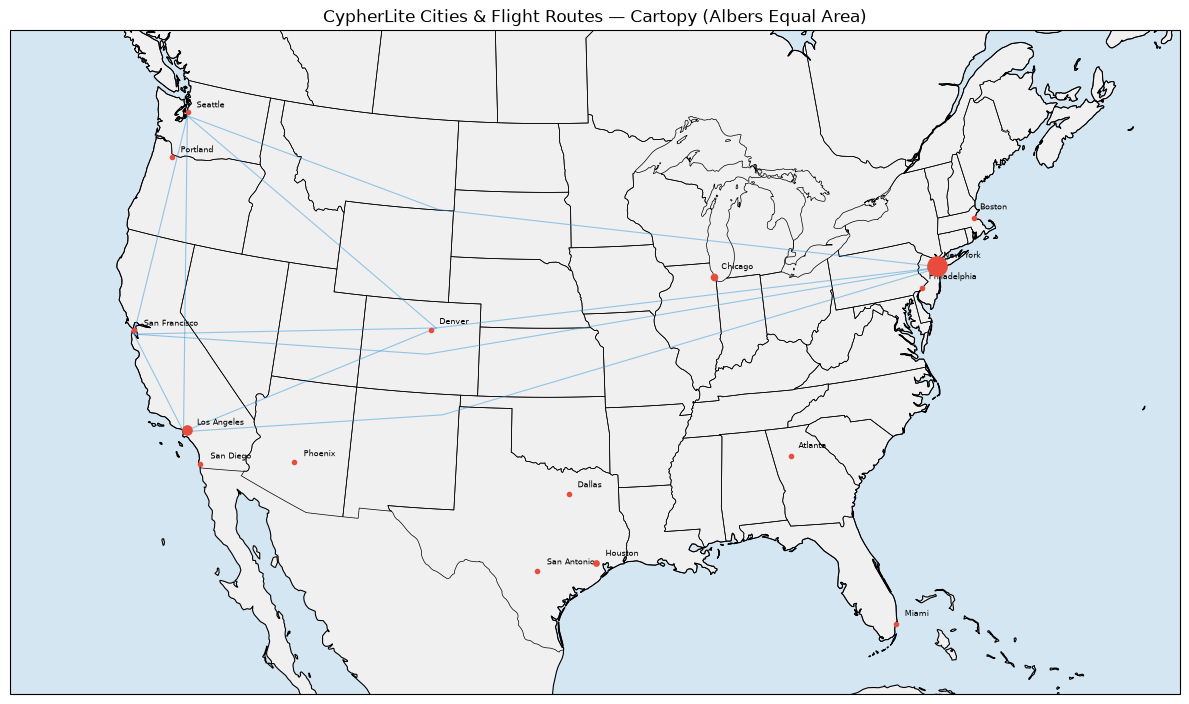

In [35]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig, ax = plt.subplots(1, 1, figsize=(12, 8),
                        subplot_kw={"projection": ccrs.AlbersEqualArea(
                            central_longitude=-98, central_latitude=39)})

ax.set_extent([-125, -66, 24, 50], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor="#f0f0f0")
ax.add_feature(cfeature.OCEAN, facecolor="#d4e6f1")

# Plot cities from Relate data
for row in city_data:
    ax.plot(row["lon"], row["lat"], "o", color="#e74c3c",
            markersize=max(3, row["pop"] / 600000),
            transform=ccrs.PlateCarree(), zorder=5)
    ax.text(row["lon"] + 0.5, row["lat"] + 0.3, row["name"],
            fontsize=6, transform=ccrs.PlateCarree())

# Plot flight routes
for rt in route_data:
    ax.plot([rt["orig_lon"], rt["dest_lon"]], [rt["orig_lat"], rt["dest_lat"]],
            color="#3498db", linewidth=0.8, alpha=0.5,
            transform=ccrs.PlateCarree())

ax.set_title("Relate Cities & Flight Routes — Cartopy (Albers Equal Area)")
plt.tight_layout()
plt.show()

---
## 19. graph-tool — Graph Analysis

`graph-tool` is a high-performance graph analysis library. Since it can be difficult to install, this section uses **NetworkX** as a widely-available alternative to demonstrate the same pattern: exporting Relate graph data for topological analysis.

In [36]:
import networkx as nx

# Export the airport route graph from Relate into NetworkX
G = nx.DiGraph()

for ap in airport_data:
    G.add_node(ap["code"], pos=(ap["lon"], ap["lat"]), name=ap["name"])

for rt in route_data:
    G.add_edge(rt["orig"], rt["dest"], weight=rt["km"])

print(f"NetworkX graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Graph metrics
print(f"\nDegree centrality:")
for node, cent in sorted(nx.degree_centrality(G).items(), key=lambda x: -x[1]):
    print(f"  {node}: {cent:.2f}")

print(f"\nBetweenness centrality:")
for node, cent in sorted(nx.betweenness_centrality(G, weight="weight").items(), key=lambda x: -x[1]):
    print(f"  {node}: {cent:.2f}")

# Shortest path by distance
path = nx.shortest_path(G, "JFK", "SEA", weight="weight")
total_km = sum(G[path[i]][path[i+1]]["weight"] for i in range(len(path) - 1))
print(f"\nShortest route JFK → SEA: {' → '.join(path)} ({total_km:,.0f} km)")

NetworkX graph: 5 nodes, 10 edges

Degree centrality:
  DEN: 1.00
  JFK: 1.00
  LAX: 1.00
  SEA: 1.00
  SFO: 1.00

Betweenness centrality:
  DEN: 0.00
  JFK: 0.00
  LAX: 0.00
  SEA: 0.00
  SFO: 0.00

Shortest route JFK → SEA: JFK → SEA (3,887 km)


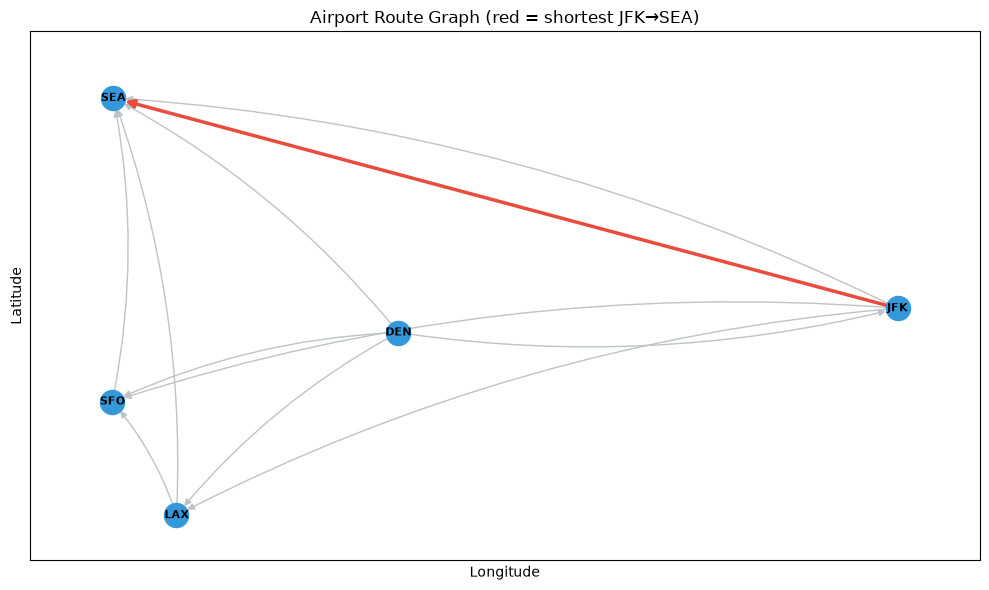

In [37]:
# Visualize the route graph with geographic positions
fig, ax = plt.subplots(figsize=(10, 6))
pos = nx.get_node_attributes(G, "pos")

nx.draw_networkx_nodes(G, pos, ax=ax, node_size=300, node_color="#3498db")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#bdc3c7", arrows=True,
                        arrowsize=10, connectionstyle="arc3,rad=0.1")

# Highlight shortest path
path_edges = [(path[i], path[i+1]) for i in range(len(path) - 1)]
nx.draw_networkx_edges(G, pos, edgelist=path_edges, ax=ax,
                        edge_color="#e74c3c", width=2.5, arrows=True, arrowsize=12)

ax.set_title("Airport Route Graph (red = shortest JFK→SEA)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

---
## 20. kepler.gl — Large-Scale Geospatial Visualization

`kepler.gl` requires a Jupyter widget environment. This section prepares the data for kepler.gl. In a live Jupyter notebook with widget support, uncomment the display line.

In [38]:
# Prepare Relate data for kepler.gl
# kepler.gl accepts pandas DataFrames directly

city_df = pd.DataFrame(city_data)
route_df = pd.DataFrame(route_data)

print("City data for kepler.gl:")
print(city_df[["name", "lat", "lon", "pop"]].head())

print("\nRoute data for kepler.gl:")
print(route_df[["orig", "orig_lat", "orig_lon", "dest", "dest_lat", "dest_lon", "km"]].head())

# To use with kepler.gl (requires jupyter widget support):
# from keplergl import KeplerGl
# kmap = KeplerGl(height=600)
# kmap.add_data(data=city_df, name="Cities")
# kmap.add_data(data=route_df, name="Routes")
# kmap

City data for kepler.gl:
          name      lat       lon      pop
0     New York  40.7128  -74.0060  8336817
1  Los Angeles  34.0522 -118.2437  3979576
2      Chicago  41.8781  -87.6298  2693976
3      Houston  29.7604  -95.3698  2320268
4      Phoenix  33.4484 -112.0740  1680992

Route data for kepler.gl:
  orig  orig_lat  orig_lon dest  dest_lat  dest_lon           km
0  DEN   39.8561 -104.6737  JFK   40.6413  -73.7781  2610.016963
1  DEN   39.8561 -104.6737  LAX   33.9425 -118.4081  1384.841693
2  DEN   39.8561 -104.6737  SFO   37.6213 -122.3790  1552.955008
3  DEN   39.8561 -104.6737  SEA   47.4502 -122.3088  1645.433792
4  LAX   33.9425 -118.4081  SFO   37.6213 -122.3790   543.610440


---
## 21. GeoViews — Interactive Geo Visualizations

GeoViews (built on HoloViews + Bokeh/Matplotlib) provides interactive geographic plots. This section prepares data and uses matplotlib for static rendering (GeoViews interactive mode requires a live Bokeh server).

In [39]:
# GeoViews can consume GeoDataFrames directly
# Here we demonstrate preparing the data from Relate → GeoDataFrame → GeoViews

try:
    import geoviews as gv
    import geoviews.feature as gf
    gv.extension("matplotlib")

    # Use the GeoDataFrame we already built from Relate
    points_gv = gv.Points(gdf, kdims=["lon", "lat"], vdims=["name", "pop"])
    plot = (gf.coastline * gf.states * points_gv).opts(
        fig_size=250, global_extent=False
    )
    print("GeoViews plot object created from Relate data")
    print(f"  Points: {len(gdf)} cities")

except ImportError:
    print("GeoViews not installed — showing data summary instead")
    print(f"GeoDataFrame ready for GeoViews: {len(gdf)} cities")
    print(gdf[["name", "state", "pop", "geometry"]].head())

GeoViews not installed — showing data summary instead
GeoDataFrame ready for GeoViews: 16 cities
          name state      pop                   geometry
0     New York    NY  8336817    POINT (-74.006 40.7128)
1  Los Angeles    CA  3979576  POINT (-118.2437 34.0522)
2      Chicago    IL  2693976   POINT (-87.6298 41.8781)
3      Houston    TX  2320268   POINT (-95.3698 29.7604)
4      Phoenix    AZ  1680992   POINT (-112.074 33.4484)


---
## 22. Putting It All Together: Relate as a Geospatial Hub

Relate stores graph-structured geospatial data with native point functions
and coordinates as ordinary properties. The Python bindings make it easy to:

1. **Store** spatial data as graph nodes/relationships with `point()` properties
2. **Query** with `point.distance()` and `point.withinBBox()`, accelerated by a `POINT INDEX`
3. **Rank and filter** by distance — nearest-N, radius and distance bands
4. **Carry geometry** as ordinary properties (GeoJSON strings) for Python-side geometry work
5. **Export** to any Python geo library (GeoPandas, Folium, Shapely, NetworkX, H3, etc.)
6. **Import** from external sources (OSMnx → Relate → analysis)

In [40]:
# Final summary: what's in our graph?
for label in ["City", "Airport", "Intersection"]:
    cursor = db.execute(
        f"MATCH (n:{label}) RETURN count(n) AS total"
    )
    print(f"  {label} nodes: {cursor.fetchone()['total']}")

cursor = db.execute(
    "MATCH (a:Airport)-[r:ROUTE]->(b:Airport) RETURN count(r) AS total"
)
print(f"  ROUTE relationships: {cursor.fetchone()['total']}")

cursor = db.execute(
    "MATCH (a:Intersection)-[s:STREET]->(b:Intersection) RETURN count(s) AS total"
)
print(f"  STREET relationships: {cursor.fetchone()['total']}")

db.close()
print("\nDatabase closed.")

  City nodes: 16
  Airport nodes: 5
  Intersection nodes: 749
  ROUTE relationships: 10
  STREET relationships: 2254

Database closed.
